
# Day 01 — Brownian Motion

**Topic:** Stochastic Processes  
**Goal:** Understand and simulate standard Brownian motion using Python.

## 1. Definition

A standard Brownian motion (Wiener process) $(W_t)_{t \geq 0}$ satisfies:

1. $W_0 = 0$.
2. It has independent increments.
3. $W_t-W_s \sim \mathcal{N}(0,t-s)$ for $0 \leq s < t$.
4. Its sample paths are continuous almost surely.

Therefore,

$$
\mathbb{E}[W_t]=0,
\qquad
\operatorname{Var}(W_t)=t.
$$

## 2. Brownian Motion Simulation

Divide the time interval $[0,T]$ into $N$ steps:

$$
\Delta t = \frac{T}{N}.
$$

Brownian increments follow:

$$
\Delta W_t = W_{t+\Delta t}-W_t
\sim \mathcal{N}(0,\Delta t).
$$

Using $Z_t \sim \mathcal{N}(0,1)$:

$$
\boxed{\Delta W_t = \sqrt{\Delta t}\,Z_t}
$$

The simulation is constructed recursively:

$$
\boxed{W_{t+\Delta t}=W_t+\sqrt{\Delta t}\,Z_t}
$$

## 3. Why Square Root of Time?

Since $\operatorname{Var}(Z_t)=1$,

$$
\operatorname{Var}(\sqrt{\Delta t}\,Z_t)
=\Delta t.
$$

Using $\Delta t Z_t$ instead would give variance
$(\Delta t)^2$, which is incorrect.

## 4. Python Implementation

We simulate one Brownian motion path with:

- $T=1$ year
- $N=252$ time steps
- $W_0=0$

## 5. Key Observations

- Brownian motion has random, independent increments.
- Its expected value remains zero.
- Its variance increases linearly with time.
- Individual paths are continuous but nowhere differentiable almost surely.

## 6. Mini Exercise

1. Generate 10 independent Brownian motion paths.
2. Change $N$ from 252 to 1,000.
3. Estimate $\mathbb{E}[W_T]$ and $\operatorname{Var}(W_T)$ using 1,000 simulations.

**Expected theoretical results:**

$$
\mathbb{E}[W_T]=0,
\qquad
\operatorname{Var}(W_T)=T.
$$


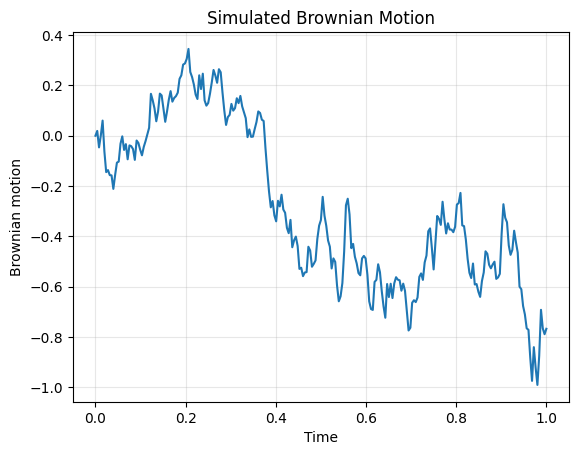

In [8]:
import numpy as np
import matplotlib.pyplot as plt

T = 1
N = 252
dt = T / N

rng = np.random.default_rng(42)  # Set a random seed for reproducibility

dW = np.sqrt(dt) * rng.normal(size=N)
W = np.insert(np.cumsum(dW), 0, 0)

t = np.linspace(0, T, N + 1)

plt.plot(t, W)
plt.xlabel("Time")
plt.ylabel("Brownian motion")
plt.title("Simulated Brownian Motion")
plt.grid(alpha=0.3)
plt.show()
